# Natural Language Processing 2 - Neural Networks and Embeddings

## Summary

In lesson 1 we turned the reviews into numbers (bag of words, TF-IDF) and trained **logistic regression**: about **80%** on the 400 test reviews. Today we open the box: logistic regression is **one artificial neuron**. We connect neurons into a **neural network**, watch how it learns (loss, backpropagation, gradient descent), and train our own network on the reviews with **word vectors** (embeddings).

**The data:** the same 2,000 movie reviews, the same training/test split as lesson 1, and our 8 tricky sentences.

**Outline** (it follows the slides):

| Section | What we do | Slides |
|---|---|---|
| 0–1 | Set up, load the reviews, training / validation / test | |
| 2 | How many features? Shrinking the vocabulary | 6–9 |
| 3 | Logistic regression = one neuron, and the bias | 10–12 |
| 4 | Tensors, a small network, forward propagation | 13–17 |
| 5 | How a network learns: loss, backpropagation, gradient descent, learning rate, local minima | 18–26 |
| 6 | One review vs many reviews: why we need validation | 28–30 |
| 7 | Word embeddings with GloVe | 31–35 |
| 8 | Our network: embeddings learned from labels | 36–42 |
| 9 | Scoreboard | 43 |
| 10 | *(Optional)* Marvin, the film chatbot with embeddings | |
| 11 | *(Optional)* A text generator: a neural network with a hidden layer | |
| 12 | Recap | 44 |

**Before class:** put `movie_reviews.csv`, the `nltk_data` folder and the GloVe file (`glove-wiki-gigaword-50.gz`, about 70 MB) in the same folder as this notebook.

## 0. Setup

We load our libraries. Our data (**movie_reviews.csv**), the GloVe word vectors (**glove-wiki-gigaword-50.gz**, about 70 MB) and the NLTK tools (in the **nltk_data** folder) must be in the same folder as this notebook.

In [1]:
import os, re, time, gzip, random
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import nltk
nltk.data.path.insert(0, "nltk_data")
from textblob import TextBlob

import torch
import torch.nn as nn

pd.set_option("display.max_colwidth", 120)
DATA_DIR = "."

## 1. Load the reviews and rebuild our three models

Same reviews and same split as lessons 1 and 2 (`random_state=42`), so the **400 test reviews are exactly the same**. As in lesson 2, we also keep 320 of the training reviews apart as a **validation set** for the neural network.

In [2]:
df = pd.read_csv(os.path.join(DATA_DIR, "movie_reviews.csv"))
df["y"] = (df["label"] == "pos").astype(int)
print("Reviews:", len(df))
display(df["label"].value_counts(), df.head(3))

Reviews: 2000


label
neg    1000
pos    1000
Name: count, dtype: int64

,fileid,label,text,y
0,neg/cv000_29416.txt,neg,"plot : two teen couples go to a church party , drink and then drive . \nthey get into an accident . \none of the guy...",0
1,neg/cv001_19502.txt,neg,the happy bastard's quick movie review \ndamn that y2k bug . \nit's got a head start in this movie starring jamie le...,0
2,neg/cv002_17424.txt,neg,it is movies like these that make a jaded movie viewer thankful for the invention of the timex indiglo watch . \nbas...,0


In [3]:
from sklearn.model_selection import train_test_split

train_df, test_df = train_test_split(df, test_size=0.2, stratify=df["y"], random_state=42)   # same split as lesson 1
print("Training reviews:", len(train_df), "| Test reviews:", len(test_df))
print("Positive share in train:", train_df["y"].mean(), "| in test:", test_df["y"].mean())

# take 20% of the training reviews out as a validation set (train_df shrinks from 1,600 to 1,280)
train_df, val_df = train_test_split(train_df, test_size=0.2, stratify=train_df["y"], random_state=42)
print("After taking out a validation set: train", len(train_df), "| validation", len(val_df), "| test", len(test_df))

Training reviews: 1600 | Test reviews: 400
Positive share in train: 0.5 | in test: 0.5
After taking out a validation set: train 1280 | validation 320 | test 400


| Set | Reviews | Used for |
|---|---|---|
| Training | 1,280 | Learn the weights |
| Validation | 320 | Practice exam: choose settings and when to stop |
| Test | 400 | Real exam: measured **once**, at the end (the same 400 as in lesson 1) |

**stratify** keeps the 50/50 mix of positive and negative reviews in every set.

<span style="color:red;"><b>Question:</b> Why don't we simply choose our settings on the test set? It is the real exam, after all.</span>

<span style="color:green;"><b>Answer:</b></span><br>
If we try many settings and keep the one with the best **test** score, we have tuned the model to these 400 reviews. The test score is then too optimistic: it no longer tells us how the model does on reviews it has never seen. That is like looking at the exam questions while studying. The validation set is our practice exam, so the test set stays a fair, real exam.

Our **8 tricky sentences** from lesson 1. They are short, made up, and hard on purpose: negation (*not good*, *didn't hate*), contrast (*but*) and sarcasm. They are **not** part of the reviews, so they test whether a model really understands, not whether it memorised.

In [4]:
tricky = pd.DataFrame({
    "sentence": [
        "This movie was great!",
        "This movie was not good.",
        "Not bad at all, I really enjoyed it.",
        "I didn't hate it.",
        "I loved the trailer, but the film was a disaster.",
        "Oh great, another two hours of my life I will never get back.",
        "The acting was terrible but the story was wonderful.",
        "Absolutely brilliant, a must-see!",
    ],
    "truth": ["pos", "neg", "pos", "pos", "neg", "neg", "pos", "pos"],
})
tricky

,sentence,truth
0,This movie was great!,pos
1,This movie was not good.,neg
2,"Not bad at all, I really enjoyed it.",pos
3,I didn't hate it.,pos
4,"I loved the trailer, but the film was a disaster.",neg
5,"Oh great, another two hours of my life I will never get back.",neg
6,The acting was terrible but the story was wonderful.,pos
7,"Absolutely brilliant, a must-see!",pos


For the scoreboard, we recompute the two methods from lesson 1: TextBlob, and logistic regression on TF-IDF trained on all 1,600 training + validation reviews.

In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer, CountVectorizer
from sklearn.linear_model import LogisticRegression

y_test = test_df["y"].values
results = {}

# 1. Rules: TextBlob (positive polarity -> pos)
textblob_test = (test_df["text"].apply(lambda t: TextBlob(t).sentiment.polarity) > 0).astype(int)
results["1. Rules: TextBlob"] = (textblob_test == y_test).mean()

# 2. TF-IDF + logistic regression, trained on all 1,600 training reviews as in lesson 1
train_full = pd.concat([train_df, val_df])
tfidf_vec = TfidfVectorizer()
X_train_tfidf = tfidf_vec.fit_transform(train_full["text"])
X_test_tfidf = tfidf_vec.transform(test_df["text"])
logreg = LogisticRegression(max_iter=1000).fit(X_train_tfidf, train_full["y"])
results["2. TF-IDF + logistic regression"] = logreg.score(X_test_tfidf, y_test)

# the same two methods on the tricky sentences
tricky["TextBlob"] = np.where(tricky["sentence"].apply(lambda s: TextBlob(s).sentiment.polarity) > 0, "pos", "neg")
tricky["Log. reg."] = np.where(logreg.predict(tfidf_vec.transform(tricky["sentence"])) == 1, "pos", "neg")

for method in ["TextBlob", "Log. reg."]:
    print(f"{method:10} tricky sentences right: {(tricky[method] == tricky['truth']).sum()} of 8")
pd.Series(results, name="test accuracy").map("{:.1%}".format)

TextBlob   tricky sentences right: 4 of 8
Log. reg.  tricky sentences right: 2 of 8


1. Rules: TextBlob                 59.5%
2. TF-IDF + logistic regression    80.2%
Name: test accuracy, dtype: str

## 2. How many features? Shrinking the vocabulary

Before we build a neural network, we look again at what logistic regression gets as input (slide 6). TF-IDF makes **one column for every word in the vocabulary**, so vocabulary size = number of features. Most cells are 0 (a review uses only a few hundred of all the words), so scikit-learn stores a **sparse matrix**: it only remembers the cells that are not 0.

Why shrink the vocabulary?
- **Rare words** (typos, names) appear too few times to learn a reliable weight.
- **Many features** make overfitting easier: the model can memorise single reviews.
- **Fewer columns** train faster and need less memory.

In [6]:
vec = TfidfVectorizer()
X_tr = vec.fit_transform(train_df["text"])
print("Features (vocabulary size):", X_tr.shape[1])
print(f"Cells that are 0: {1 - X_tr.nnz / (X_tr.shape[0] * X_tr.shape[1]):.1%}")
print("Different words in an average review:", round(X_tr.nnz / X_tr.shape[0]))

Features (vocabulary size): 33169
Cells that are 0: 99.0%
Different words in an average review: 333


We try several settings, each fitted on the 1,280 **training** reviews and checked on the 320 **validation** reviews (never the test set):

| Setting | What it does |
|---|---|
| `min_df=2` / `min_df=5` | drop words that appear in fewer than 2 / 5 reviews (the rare tail) |
| `max_features=10000` | keep only the 10,000 most frequent words |
| `stop_words="english"` | drop common words like *the*, *and*, *is*, and also *not* |

In [7]:
settings = {
    "default": {},
    "min_df=2": {"min_df": 2},
    "min_df=5": {"min_df": 5},
    "max_features=10000": {"max_features": 10000},
    "stop_words": {"stop_words": "english"},
    "max_features + stop_words": {"max_features": 10000, "stop_words": "english"},
}
rows = []
for name, kwargs in settings.items():
    v = TfidfVectorizer(**kwargs)
    X = v.fit_transform(train_df["text"])
    m = LogisticRegression(max_iter=1000).fit(X, train_df["y"])
    rows.append({"setting": name, "features": X.shape[1],
                 "validation acc": round(100 * m.score(v.transform(val_df["text"]), val_df["y"]), 1)})
pd.DataFrame(rows)

,setting,features,validation acc
0,default,33169,81.6
1,min_df=2,19396,81.6
2,min_df=5,10132,82.2
3,max_features=10000,10000,82.8
4,stop_words,32865,81.2
5,max_features + stop_words,10000,81.2


<span style="color:red;"><b>Question:</b> Which setting would you choose, and why? Is a difference of 1% on 320 validation reviews a big difference?</span>

<span style="color:green;"><b>Answer:</b></span><br>
`max_features=10000` scores best (82.8%) with 3 times fewer features than the default. But 1% of 320 reviews is only about **3 reviews**, so all settings are almost equally good. The real win is that a **smaller vocabulary gives the same accuracy** with less memory and faster training.

Stop words don't help: the list also removes *not*, *no*, *but* and *very*, words that matter for sentiment.

Look at all words of the training reviews sorted by how often they are used.

<span style="color:red;"><b>Question:</b> Why do <code>min_df</code> and <code>max_features</code> keep the <b>frequent</b> words, when stop words (the most frequent words) are thrown away?</span>

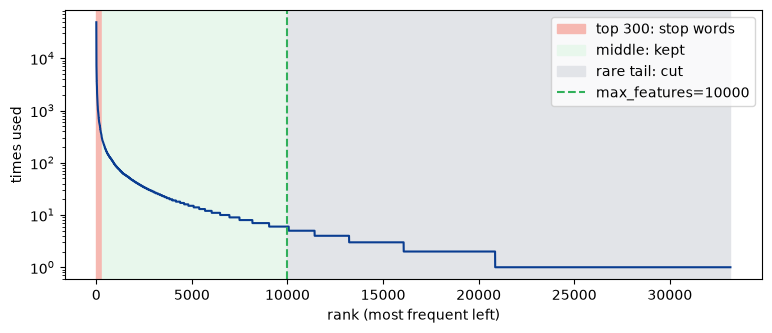

the        rank      1  used 48,906×
not        rank     24  used  3,673×
great      rank    124  used    722×
boring     rank    524  used    168×
excellent  rank    741  used    123×
awful      rank  1,019  used     87×
dismal     rank  5,857  used     12×
splendid   rank  8,354  used      7×
Top 300 words = 59% of all words read
The 10,000th word is used 6×
Words used only once: 12,310 (37% of the vocabulary)


In [8]:
cv = CountVectorizer().fit(train_df["text"])
freq = np.asarray(cv.transform(train_df["text"]).sum(axis=0)).ravel()   
order = np.argsort(-freq)                                             
names = cv.get_feature_names_out()
rank = {names[i]: r + 1 for r, i in enumerate(order)}

plt.figure(figsize=(9, 3.5))
plt.plot(np.arange(1, len(order) + 1), freq[order], color="#0A3D91")
plt.axvspan(1, 300, color="#F6B8B1", label="top 300: stop words")
plt.axvspan(300, 10000, color="#E8F7EC", label="middle: kept")
plt.axvspan(10000, len(order), color="#E2E4E8", label="rare tail: cut")
plt.axvline(10000, color="#30B05A", ls="--", label="max_features=10000")
plt.yscale("log"); plt.xlabel("rank (most frequent left)"); plt.ylabel("times used"); plt.legend()
plt.show()

for w in ["the", "not", "great", "boring", "excellent", "awful", "dismal", "splendid"]:
    print(f"{w:10} rank {rank[w]:>6,}  used {freq[cv.vocabulary_[w]]:>6,}×")
print(f"Top 300 words = {freq[order[:300]].sum() / freq.sum():.0%} of all words read")
print(f"The 10,000th word is used {freq[order[9999]]}×")
print(f"Words used only once: {(freq == 1).sum():,} ({(freq == 1).mean():.0%} of the vocabulary)")

<span style="color:green;"><b>Answer:</b></span><br>
The two cuts work at **opposite ends** of the graph:<br>

**Stop words** cut the **top**: a fixed list of very common words (*the*, *and*, *is*...). The top 300 words alone make up 59% of everything we read, but they say little about sentiment.<br>
**`min_df` and `max_features`** cut the **rare tail**: the 10,000th word is used only 6 times, and 37% of the vocabulary is used only **once**. One example is not enough to learn a reliable weight.<br>

Most sentiment words (*great*, *boring*, *excellent*, *awful*) live in the **middle** and survive both cuts.

## 3. Logistic regression = one neuron

A neuron (slide 10): **z = w·x + b**, then an **activation**. Logistic regression is exactly that:

- **inputs x:** the TF-IDF values of the words of one review (36,352 numbers, mostly 0)
- **weights w:** one per word, learned (so 36,352 weights)
- **bias b:** a starting value, always added
- **activation:** the sigmoid, p = 1 / (1 + e⁻ᶻ), a probability between 0 and 1

**w·x** means: multiply every input by its weight and add everything up.

<span style="color:red;"><b>Question:</b> If logistic regression really is one neuron, we can compute its prediction by hand with z = w·x + b and the sigmoid. Do we get the same probability as scikit-learn for the first test review? Is the prediction right?</span>

In [ ]:
x = X_test_tfidf[0].toarray()[0]      
w = logreg.coef_[0]               
b = logreg.intercept_[0]              

z = np.dot(w, x) + b                     
p = 1 / (1 + np.exp(-z))              

print("review:", test_df["text"].iloc[0][:150], "...")
print(f"different words in it: {(x > 0).sum()} of {len(x):,} inputs\n")
print(f"words: w·x        = {np.dot(w, x):.2f}")
print(f"bias b            = {b:.2f}")
print(f"z = w·x + b       = {z:.3f}")
print(f"our probability   = {p:.4f}")
print(f"scikit-learn says = {logreg.predict_proba(X_test_tfidf[0])[0, 1]:.4f}")
print(f"before reading any word: sigmoid(b) = {1 / (1 + np.exp(-b)):.2f}")
print(f"true label: {'pos' if y_test[0] == 1 else 'neg'} | predicted: {'pos' if p > 0.5 else 'neg'}")

# which words pushed hardest? (weight × input, for the words in this review)
push = pd.Series(w * x, index=tfidf_vec.get_feature_names_out())[x > 0].sort_values()
display(pd.concat([push.head(5), push.tail(5)]).round(3).to_frame("push w·x"))

review: dr dolittle ( 20th century fox ) running time : 1 hour 25 minutes starring eddie murphy directed by betty thomas riding high on the success of the nut ...
different words in it: 257 of 36,352 inputs

words: w·x        = -0.16
bias b            = -0.48
z = w·x + b       = -0.639
our probability   = 0.3456
scikit-learn says = 0.3456
before reading any word: sigmoid(b) = 0.38
true label: neg | predicted: neg


,push w·x
to,-0.131
better,-0.078
boring,-0.072
dumb,-0.067
movie,-0.064
most,0.050
of,0.051
is,0.073
and,0.326
the,0.358


<span style="color:green;"><b>Answer:</b></span><br>
Yes: our hand computation gives **exactly** the same probability as scikit-learn (0.3456). Logistic regression **is** one neuron: 36,352 inputs, 36,352 weights, one bias, a sigmoid.

The review (*Dr. Dolittle*, "this abysmal comedy") is negative, and p = 0.35 < 0.5, so the prediction is **right**. The words *boring* and *dumb* push down, as we would expect. But look at the top: *the* and *and* push **up** the most. They are in every review... keep that in mind for the next question.

<span style="color:red;"><b>Question:</b> The reviews are 50/50, so why is the bias negative (−0.48) and not 0? (slide 11)</span>

In [10]:
pushes = X_train_tfidf @ w                           
print(f"average push of the words (w·x) on the training reviews: {pushes.mean():+.2f}")
print(f"bias: {b:+.2f}  -> together about 0, so an average review lands near p = 0.5\n")

y_train_full = train_full["y"].values
print(f"average push of positive reviews: {pushes[y_train_full == 1].mean():+.2f}")
print(f"average push of negative reviews: {pushes[y_train_full == 0].mean():+.2f}\n")

# which words cause the average push? (weight × average TF-IDF value)
avg_push = pd.Series(np.asarray(X_train_tfidf.multiply(w).mean(axis=0)).ravel(),
                     index=tfidf_vec.get_feature_names_out()).sort_values()
display(avg_push.tail(4).round(2).to_frame("average push"))

average push of the words (w·x) on the training reviews: +0.48
bias: -0.48  -> together about 0, so an average review lands near p = 0.5

average push of positive reviews: +1.12
average push of negative reviews: -0.16



,average push
of,0.12
is,0.15
and,0.34
the,0.34


<span style="color:green;"><b>Answer:</b></span><br>
The bias does not balance the **classes** (they are 50/50), it balances the **words**. Very common words like *the* and *and* got positive weights, and because they are in every review they push **every** review up, by about +0.48 on average. The bias learns −0.48 to cancel that, so an average review lands at z ≈ 0, p = 0.5.

Another way to see it: positive reviews push +1.12 on average and negative reviews −0.16. The bias moves the dividing line to about halfway between them.

Why do *the* and *and* get positive weights at all? In our training reviews, positive reviews use them slightly **more often** (for example *and*: TF-IDF 0.142 in positive vs 0.129 in negative reviews). The difference is tiny, but the model uses every small difference it can find, even in words that mean nothing on their own.

### Threshold or bias?

Normally a review is called positive when p > 0.5. Sometimes we want a different **threshold**, for example 0.4, to catch more positive reviews (and accept more mistakes on negative ones).

Moving the threshold from 0.5 to 0.4 has exactly the same effect as keeping 0.5 and **adding about +0.41 to the bias**. Why 0.41? The sigmoid gives p = 0.4 at z = −0.41, so shifting every z up by 0.41 moves that point to z = 0, where p = 0.5.

In [11]:
probs = logreg.predict_proba(X_test_tfidf)[:, 1]
z_all = np.log(probs / (1 - probs))          
shift = -np.log(0.4 / 0.6) # 0.405

with_threshold = (probs > 0.4).astype(int) # threshold moved by hand
with_bias = (1 / (1 + np.exp(-(z_all + shift))) > 0.5).astype(int) # bias changed, threshold stays 0.5
print("bias shift:", round(shift, 3), "| same predictions:", (with_threshold == with_bias).all(), "\n")

rows = []
for t in [0.5, 0.4]:
    pred = (probs > t).astype(int)
    rows.append({"threshold": t, "called positive": pred.sum(),
                 "real positives caught (of 200)": ((pred == 1) & (y_test == 1)).sum(),
                 "negatives called positive": ((pred == 1) & (y_test == 0)).sum(),
                 "accuracy": f"{(pred == y_test).mean():.1%}"})
pd.DataFrame(rows)

bias shift: 0.405 | same predictions: True 



,threshold,called positive,real positives caught (of 200),negatives called positive,accuracy
0,0.5,217,169,48,80.2%
1,0.4,306,196,110,71.5%


<span style="color:red;"><b>Question:</b> With threshold 0.4, the model catches 27 more positive reviews, but the accuracy drops from 80.2% to 71.5%. When would that still be a good trade?</span>

<span style="color:green;"><b>Answer:</b></span><br>
When **missing** a case costs more than a false alarm. For example: a cinema wants to find every happy customer to ask for a public review, and a few wrong ones don't hurt. Or the other way round: a support team wants to find every **unhappy** customer, so it lowers the threshold for *negative*.

The model **learns** the bias, but the **threshold** is our choice: the model only gives a probability, and 0.5 is a convention. Moving the threshold is the same as moving the learned bias by hand. Which threshold is right depends on what a mistake costs: accuracy counts a missed positive and a false alarm as equally bad, which is often not true.

## 4. A small network: tensors and forward propagation

From now on we use **PyTorch**, a library for neural networks. It works with **tensors**: arrays of numbers, like NumPy arrays, that can also remember how they were computed (needed for backpropagation later).

We build the small network from the slides (13–17), with made-up weights:

- **3 inputs:** how often a review uses *great*, *plot*, *boring*. Our review: great 1×, plot 2×, boring 0×.
- **2 hidden neurons** z1, z2, each with its own 3 weights (the matrix **W**).
- **1 output** y, with 2 weights from z1 and z2 (the vector **v**).

In [12]:
x = torch.tensor([1.0, 2.0, 0.0])   
W = torch.tensor([[0.3, 0.5, 0.8],       
                  [0.4, 0.2, 0.0]])       
v = torch.tensor([0.9, 0.7])     

print("x:", x, "shape", tuple(x.shape), "-> 3 inputs")
print("W:", W, "shape", tuple(W.shape), "-> 2 neurons × 3 inputs")
print("v:", v, "shape", tuple(v.shape), "-> 2 hidden neurons into 1 output")

x: tensor([1., 2., 0.]) shape (3,) -> 3 inputs
W: tensor([[0.3000, 0.5000, 0.8000],
        [0.4000, 0.2000, 0.0000]]) shape (2, 3) -> 2 neurons × 3 inputs
v: tensor([0.9000, 0.7000]) shape (2,) -> 2 hidden neurons into 1 output


After the weighted sum, every neuron applies an **activation function**. Here are the four common ones, all applied to z = −0.64 (the *Dr. Dolittle* review from section 3):

- **sigmoid:** squeezes any number into 0 to 1, a probability (logistic regression)
- **ReLU:** keeps positive numbers, turns negative ones into 0 (hidden layers)
- **tanh:** squeezes into −1 to 1
- **softmax:** turns several scores into probabilities that add up to 1 (for more than two classes)

sigmoid: 0.35
ReLU:    0.0
tanh:    -0.56
softmax: [0.67, 0.24, 0.09] (adds up to 1)


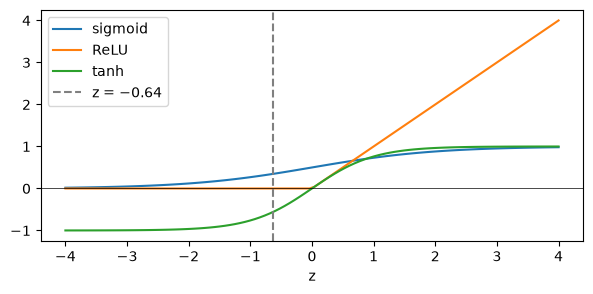

In [13]:
z_review = torch.tensor(-0.64)
print("sigmoid:", round(torch.sigmoid(z_review).item(), 2))
print("ReLU:   ", round(torch.relu(z_review).item(), 2))
print("tanh:   ", round(torch.tanh(z_review).item(), 2))

scores = torch.tensor([2.0, 1.0, 0.0])      # pos / neutral / neg
print("softmax:", [round(t, 2) for t in torch.softmax(scores, dim=0).tolist()], "(adds up to 1)")

zs = torch.linspace(-4, 4, 100)
plt.figure(figsize=(7, 3))
for name, f in [("sigmoid", torch.sigmoid), ("ReLU", torch.relu), ("tanh", torch.tanh)]:
    plt.plot(zs, f(zs), label=name)
plt.axvline(-0.64, color="gray", ls="--", label="z = −0.64")
plt.axhline(0, color="black", lw=0.5)
plt.xlabel("z"); plt.legend(); plt.show()

<span style="color:red;"><b>Question:</b> ReLU turns −0.64 into 0. Why would ReLU be a bad choice for the <b>output</b> of our sentiment model?</span>

<span style="color:green;"><b>Answer:</b></span><br>
ReLU gives 0 for **every** negative number, so a slightly negative and a very negative review look the same. And above 0 it has no upper limit, so the result is not a probability. For the output we want a number between 0 and 1: the **sigmoid**. ReLU is used **inside** the network, in the hidden layers.

**Forward propagation**: data flows from the inputs to the output. In every neuron: weighted sum, then activation.

A whole layer is one **matrix multiplication** `W @ x` (slide 17): every row of W times x gives one neuron's weighted sum. For z1: 0.3·1 + 0.5·2 + 0.8·0 = **1.3**. For z2: 0.4·1 + 0.2·2 + 0.0·0 = **0.8**. Then **ReLU** keeps positive numbers and turns negative ones into 0.

In [14]:
sums = W @ x            
z = torch.relu(sums)        
y = v @ z           

print("weighted sums  =", [round(t, 2) for t in sums.tolist()])
print("after ReLU     =", [round(t, 2) for t in z.tolist()], "(both positive, so ReLU keeps them)")
print("y = 0.9·1.3 + 0.7·0.8 =", round(y.item(), 2))

weighted sums  = [1.3, 0.8]
after ReLU     = [1.3, 0.8] (both positive, so ReLU keeps them)
y = 0.9·1.3 + 0.7·0.8 = 1.73


<span style="color:red;"><b>Question:</b> For our review, ReLU changed nothing (both sums were positive). So what happens in general if we remove the activation from the hidden layer? Is the network still more powerful than logistic regression?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Without an activation, y = v·(W·x) = (v·W)·x. For our numbers, v·W = (0.55, 0.59, 0.72): **one neuron with 3 weights** gives exactly the same y = 1.73. Two layers of weighted sums are just one weighted sum, and 100 layers would be too. Without a bend the network is **no better than one neuron** (slide 14).

ReLU did nothing for our review only because all our made-up weights are positive, so the sums are never negative. In a trained network many weights are negative, ReLU cuts many sums to 0, and that bend is what lets the network learn more than one weighted sum.

In [15]:
print("two layers, no ReLU:", round((v @ (W @ x)).item(), 2))
print("one neuron, weights v·W =", [round(t, 2) for t in (v @ W).tolist()], "->", round(((v @ W) @ x).item(), 2))

two layers, no ReLU: 1.73
one neuron, weights v·W = [0.55, 0.59, 0.72] -> 1.73


## 5. How a network learns

Training repeats four steps:

1. **Forward:** compute the prediction y.
2. **Loss:** one number that says how wrong y is.
3. **Backward** (backpropagation): find out how much every weight is to blame.
4. **Update** (gradient descent): move every weight a little to make the loss smaller.

On real data we don't do this one review at a time: a **batch** is a group of reviews (for example 32) used for one update, and an **epoch** is one pass through all training reviews.

We do it on our small network with the right answer **1.0** (a made-up example).

### Loss

- **MSE** (mean squared error), when we predict a number: (y − right answer)². Our network: (1.73 − 1.0)² = 0.53.
- **Cross-entropy**, when we predict a probability: −log(probability given to the right answer). Sure and right → close to 0. Sure and wrong → very large.

In [ ]:
target = 1.0
mse = (y - target) ** 2
print("MSE loss:", round(mse.item(), 4), " = (1.73 − 1.0)²\n")

for p_right in [0.9, 0.5, 0.1, 0.01]:
    print(f"cross-entropy if the right answer gets {p_right}: {-np.log(p_right):.2f}")

#Dr. Dolittle (section 3) is negative, the model gave 'neg' 1 − 0.35 = 0.65
print(f"\nDr. Dolittle: right answer gets 0.65 -> cross-entropy {-np.log(0.65):.2f}")


MSE loss: 0.5329  = (1.73 − 1.0)²

cross-entropy if the right answer gets 0.9: 0.11
cross-entropy if the right answer gets 0.5: 0.69
cross-entropy if the right answer gets 0.1: 2.30
cross-entropy if the right answer gets 0.01: 4.61

Dr. Dolittle: right answer gets 0.65 -> cross-entropy 0.43


<span style="color:red;"><b>Question:</b> Giving the right answer 0.1 costs 2.30, giving it 0.01 costs 4.61. Why is it good that cross-entropy punishes "sure and wrong" so hard?</span>

<span style="color:green;"><b>Answer:</b></span><br>
A model that says "1% chance this is positive" about a positive review is **confidently wrong**, which is worse than being unsure. The big loss makes the gradients big, so training fixes these mistakes first. A model that is unsure (0.5) gets a medium loss of 0.69: it has not learned anything yet, but it is not misleading either.

### Backpropagation

The **gradient** of a weight is its **blame**: how much the loss goes up if we make that weight a little bigger.

- **Positive** gradient: the weight is too big, make it smaller.
- **Negative** gradient: the weight is too small, make it bigger.
- **0**: this weight had no effect on the loss.

Backpropagation starts at the loss and **follows the paths backwards** (slide 21): the blame of a weight = the error signal × everything on its path to the output.

In PyTorch we mark the weights with `requires_grad=True`. Then `loss.backward()` computes the gradient of **every** weight in **one backward pass**.

<span style="color:red;"><b>Question:</b> Before you run the next cell: y = 1.73 is too big. Will the gradients be positive or negative? Which weights will get a gradient of exactly 0?</span>

In [17]:
W = torch.tensor([[0.3, 0.5, 0.8], [0.4, 0.2, 0.0]], requires_grad=True)
v = torch.tensor([0.9, 0.7], requires_grad=True)

y = v @ torch.relu(W @ x)          # 1. forward
loss = (y - target) ** 2           # 2. loss
loss.backward()                    # 3. backward: all gradients at once

print(f"y = {y.item():.2f}, right answer 1.0 -> y is too big, loss {loss.item():.2f}")
print("error signal 2·(y − 1.0) =", round(2 * (y.item() - target), 2), "\n")
print("gradient of weight z1 → y, z2 → y:       ", [round(t, 2) for t in v.grad.tolist()])
print("gradients into z1 (great, plot, boring):", [round(t, 2) for t in W.grad[0].tolist()])
print("gradients into z2 (great, plot, boring):", [round(t, 2) for t in W.grad[1].tolist()])

y = 1.73, right answer 1.0 -> y is too big, loss 0.53
error signal 2·(y − 1.0) = 1.46 

gradient of weight z1 → y, z2 → y:        [1.9, 1.17]
gradients into z1 (great, plot, boring): [1.31, 2.63, 0.0]
gradients into z2 (great, plot, boring): [1.02, 2.04, 0.0]


<span style="color:green;"><b>Answer:</b></span><br>
All gradients are **positive**: y is too big, so every weight that pushed y up is to blame and should get smaller. The weights from *boring* get **0**: its input was 0, so they had no effect on y.

Follow the paths (slide 21), same numbers as on the slides:
- weight z1 → y: error signal × z1 = 1.46 × 1.3 = **1.90**
- weight plot → z1: error signal × weight z1 → y × input plot = 1.46 × 0.9 × 2 = **2.63**

### Gradient descent on one weight

Move only the weight z1 → y, keep all others fixed:

**new w = w − learning rate × gradient**

- The **minus** means: go **against** the blame. Positive gradient → the weight gets smaller.
- The **learning rate** is the size of the step: how far we move each time.

We try two learning rates, 0.1 and 0.5, for 8 steps each.

learning rate 0.1                       learning rate 0.5               \
               step     w   loss gradient              step     w   loss   
0                 0  0.90  0.533     1.90                 0  0.90  0.533   
1                 1  0.71  0.234     1.26                 1 -0.05  0.254   
2                 2  0.58  0.102     0.83                 2  0.61  0.121   
3                 3  0.50  0.045     0.55                 3  0.15  0.058   
4                 4  0.45  0.020     0.36                 4  0.47  0.027   
5                 5  0.41  0.009     0.24                 5  0.25  0.013   
6                 6  0.39  0.004     0.16                 6  0.40  0.006   
7                 7  0.37  0.002     0.11                 7  0.30  0.003   

            
  gradient  
0     1.90  
1    -1.31  
2     0.90  
3    -0.62  
4     0.43  
5    -0.30  
6     0.20  
7    -0.14

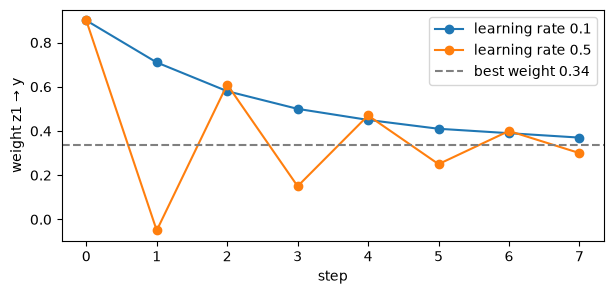

In [ ]:
def descend(lr, steps=8):
    w1 = torch.tensor(0.9, requires_grad=True)
    rows = []
    for step in range(steps):
        y = w1 * 1.3 + 0.7 * 0.8                 
        loss = (y - target) ** 2
        loss.backward()
        rows.append((step, round(w1.item(), 2), round(loss.item(), 3), round(w1.grad.item(), 2)))
        with torch.no_grad():
            w1 -= lr * w1.grad                  
        w1.grad.zero_()                          
    return pd.DataFrame(rows, columns=["step", "w", "loss", "gradient"])

display(pd.concat([descend(0.1), descend(0.5)], axis=1, keys=["learning rate 0.1", "learning rate 0.5"]))

plt.figure(figsize=(7, 3))
for lr in [0.1, 0.5]:
    plt.plot(descend(lr)["w"], marker="o", label=f"learning rate {lr}")
plt.axhline((1.0 - 0.7 * 0.8) / 1.3, color="gray", ls="--", label="best weight 0.34")
plt.xlabel("step"); plt.ylabel("weight z1 → y"); plt.legend(); plt.show()

<span style="color:red;"><b>Question:</b> Both learning rates bring the loss close to 0. What is different about the way they get there?</span>

<span style="color:green;"><b>Answer:</b></span><br>
With **0.1** the weight walks steadily downhill towards the best value 0.34. With **0.5** the first step is so big that the weight jumps **past** the best value (to −0.05), then back, then past again: it **zigzags**. Here it still arrives, but a bit bigger and it would never settle (we will see that in a moment).

### Updating every weight

In real training we don't move one weight, we move **all** weights at once, each against its own blame. Then we run forward again to see the new y.

<span style="color:red;"><b>Question:</b> With one weight, learning rate 0.1 worked well. Now all 8 weights move at the same time, each with learning rate 0.1. Do you expect y to land closer to 1.0, or to jump past it?</span>

<span style="color:green;"><b>Answer:</b></span><br>
It jumps **past** 1.0: from 1.73 down to 0.63. Every weight takes its own step to make y smaller, and all these steps **add up**. A step size that was fine for one weight is too big for many. With half the learning rate (0.05), y lands at 1.13, much closer. The more weights move together, the smaller the learning rate usually has to be.

In [19]:
def one_update(lr):
    W = torch.tensor([[0.3, 0.5, 0.8], [0.4, 0.2, 0.0]], requires_grad=True)
    v = torch.tensor([0.9, 0.7], requires_grad=True)
    loss = (v @ torch.relu(W @ x) - target) ** 2      
    loss.backward()                             
    with torch.no_grad():
        W -= lr * W.grad                  
        v -= lr * v.grad
        y_new = v @ torch.relu(W @ x)             
    return W.detach(), v.detach(), y_new.item()

W_new, v_new, y_new = one_update(0.1)
print("new W:", [[round(t, 2) + 0.0 for t in row] for row in W_new.tolist()])   # + 0.0 avoids printing -0.0
print("new v:", [round(t, 2) for t in v_new.tolist()])
print(f"learning rate 0.1:  y = {y_new:.2f}, loss = {(y_new - 1) ** 2:.2f}")
_, _, y05 = one_update(0.05)
print(f"learning rate 0.05: y = {y05:.2f}, loss = {(y05 - 1) ** 2:.2f}")

new W: [[0.17, 0.24, 0.8], [0.3, 0.0, 0.0]]
new v: [0.71, 0.58]
learning rate 0.1:  y = 0.63, loss = 0.14
learning rate 0.05: y = 1.13, loss = 0.02


### The learning rate

Think of walking down into a valley **blindfolded**: you feel the slope under your feet (the gradient) and take a step downhill. The learning rate is the **length of your step**.

We try three learning rates, 0.02, 0.1 and 0.7, for 6 steps each and look at the loss.

learning rate 0.02: [0.533, 0.463, 0.403, 0.35, 0.304, 0.265]
learning rate 0.1: [0.533, 0.234, 0.102, 0.045, 0.02, 0.009]
learning rate 0.7: [0.533, 0.994, 1.855, 3.462, 6.46, 12.055]


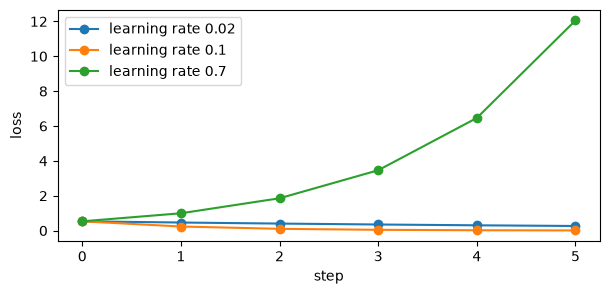

In [20]:
plt.figure(figsize=(7, 3))
for lr in [0.02, 0.1, 0.7]:
    losses = descend(lr, steps=6)["loss"]
    print(f"learning rate {lr}:", losses.tolist())
    plt.plot(losses, marker="o", label=f"learning rate {lr}")
plt.xlabel("step"); plt.ylabel("loss"); plt.legend(); plt.show()

<span style="color:red;"><b>Question:</b> Which learning rate is too small, which is good, and which is too big?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- **0.02:** the loss goes down, but very slowly: tiny steps, it takes forever to reach the bottom.
- **0.1:** steady steps, the loss is almost 0 after 6 steps.
- **0.7:** every step jumps over the bottom of the valley and lands **higher** on the other side: the loss explodes. With 0.5 we saw the start of this, the zigzag.

There is no learning rate that is right for every problem: we saw that 0.1 was good for one weight but too big when all weights moved. In section 8 we use the **Adam** optimizer: it adapts the step size for every weight while training. We still give it a starting learning rate (`lr=0.005`).

<span style="color:red;"><b>Question:</b> For one weight we computed the best value directly with algebra: (1.0 − 0.56) / 1.3 = 0.34. Why do neural networks take many small steps instead of solving it like that?</span>

<span style="color:green;"><b>Answer:</b></span><br>
With one weight and one review, algebra works. With **millions of weights**, many reviews and ReLU bends, there is no formula to solve. What is always possible: compute the slope of every weight (backpropagation), step a little downhill, repeat. That is **gradient descent**. Even logistic regression in scikit-learn learns step by step (`max_iter=1000` is the maximum number of steps).

The price: walking downhill blindfolded, we can get stuck in a small dip that is not the lowest point, a **local minimum**. In practice, with many weights this is rarely a big problem.

## 6. One review vs many reviews

We write a review as its three counts **(great, plot, boring)**: (0, 0, 4) means *boring* 4 times.

- **A:** train our small network on its **one** review (1, 2, 0), right answer 1.0.
- **B:** train the same network, plus a bias in every neuron, on **8** made-up reviews: 4 good ones with *great* (right answer 1.0) and 4 bad ones with *boring* (right answer 0.0).

Then both score reviews they have **not** seen, like (3, 0, 0) and (0, 0, 4).

<span style="color:red;"><b>Question:</b> Before you run the next cell: network A has only ever seen one good review. What score do you think it gives the very bad review (0, 0, 4)?</span>

In [21]:
def train_small(X, T, steps, lr=0.05, with_bias=False):
    W = torch.tensor([[0.3, 0.5, 0.8], [0.4, 0.2, 0.0]], requires_grad=True)
    v = torch.tensor([0.9, 0.7], requires_grad=True)
    b1 = torch.zeros(2, requires_grad=True); b2 = torch.zeros(1, requires_grad=True)
    params = [W, v] + ([b1, b2] if with_bias else [])
    for _ in range(steps):
        y = torch.relu(X @ W.T + b1) @ v + b2  
        loss = ((y - T) ** 2).mean()   
        for p_ in params: p_.grad = None
        loss.backward()   
        with torch.no_grad():
            for p_ in params: p_ -= lr * p_.grad        
    print(f"final training loss: {loss.item():.4f} | weights from boring into z1, z2:",
          [round(t, 2) for t in W[:, 2].tolist()])

    def score(review):   
        r = torch.tensor(review, dtype=torch.float)
        return (torch.relu(r @ W.T + b1) @ v + b2).item()
    return score

print("A:", end=" "); net_A = train_small(torch.tensor([[1., 2., 0.]]), torch.tensor([1.]), steps=30)
reviews_B = [[1, 2, 0], [2, 0, 0], [3, 1, 0], [1, 0, 0], [0, 1, 2], [0, 2, 1], [0, 0, 3], [1, 1, 2]]
print("B:", end=" "); net_B = train_small(torch.tensor(reviews_B, dtype=torch.float),
                                          torch.tensor([1., 1, 1, 1, 0, 0, 0, 0]), steps=500, with_bias=True)

new_reviews = {"the training review (1, 2, 0)": [1, 2, 0], "great × 3 (3, 0, 0)": [3, 0, 0],
               "boring × 3 (0, 1, 3)": [0, 1, 3], "boring × 4 (0, 0, 4)": [0, 0, 4]}
pd.DataFrame({"A: 1 review": {k: round(net_A(r), 2) for k, r in new_reviews.items()},
              "B: 8 reviews": {k: round(net_B(r), 2) for k, r in new_reviews.items()}})

A: final training loss: 0.0000 | weights from boring into z1, z2: [0.8, 0.0]
B: final training loss: 0.0005 | weights from boring into z1, z2: [0.26, -0.77]


,A: 1 review,B: 8 reviews
"the training review (1, 2, 0)",1.00,0.98
"great × 3 (3, 0, 0)",1.15,1.02
"boring × 3 (0, 1, 3)",2.19,-0.04
"boring × 4 (0, 0, 4)",2.51,-0.04


<span style="color:green;"><b>Answer:</b></span><br>
**Why A goes wrong.** A learns only from the review (1, 2, 0). There *boring* is 0, so during backpropagation the weights from *boring* always get **blame 0** (just like in section 5). They never move and keep their random start: 0.8 into z1, 0.0 into z2.

Now A scores the very bad review (0, 0, 4):
- z1 = ReLU(0.8 × 4) = 3.2, z2 = 0
- y = 0.79 × 3.2 = **2.51**, higher than the good training review (1.00)

A has not learned that *boring* is bad. It has never been told anything about *boring*, so it uses a random weight, and here the random weight happens to say "more boring = better". Its training loss is 0 because it **memorised** its one review, not because it understood anything.

**Why B gets it right.** B also sees bad reviews with *boring*, and their right answer is 0. Now *boring* gets blame, and its weight into z2 is pushed down to **−0.77**. For (0, 0, 4), z2 becomes negative and ReLU turns it into 0. What is left gives y = **−0.04**, almost exactly the right answer for a bad review.

**The lesson:**
- A model can only learn from what is **in** its training data. A word it never saw, or never saw in a bad review, stays random.
- A training loss of 0 does **not** prove the model works. A and B both reach 0, and only one of them is useful.
- The only way to find out is to score reviews the model has **never seen**. That is the **validation set**.

## 7. Word embeddings with GloVe

An **embedding** gives every word a list of numbers. **GloVe** (Stanford): 400,000 words, **50 numbers each**, learned from Wikipedia and news by looking at which words appear **together**.

<span style="color:red;"><b>Question:</b> In TF-IDF, every word is its own column. How similar are the columns for <i>great</i> and <i>excellent</i>? What does that mean for a review that says <i>splendid</i>, a word the model saw only 7 times in training?</span>

<span style="color:green;"><b>Answer:</b></span><br>
Not similar at all: they are two separate columns, so for the model *great* and *excellent* are as different as *great* and *popcorn*. Everything it knows about a word it must learn from the reviews that contain **that** word. A rare word like *splendid* (7 times, section 2) gets an unreliable weight.

An **embedding** fixes this: it gives every word a **list of numbers** (a vector), and words with similar meanings get similar vectors. Then what the model learns about *great* also helps with *splendid*.

**GloVe** (Stanford) is a ready-made embedding: 400,000 words, **50 numbers each**, learned from Wikipedia and news by looking at which words appear **together**. We load the 100,000 most common words.

In [22]:
candidates = ["glove-wiki-gigaword-50.gz", "glove-wiki-gigaword-50", "glove-wiki-gigaword-50.txt"]
found = [f for f in candidates if os.path.exists(os.path.join(DATA_DIR, f))]
if not found:
    raise FileNotFoundError("GloVe file not found: put glove-wiki-gigaword-50.gz in the same folder as this notebook.")
GLOVE_FILE = os.path.join(DATA_DIR, found[0])

open_file = gzip.open if GLOVE_FILE.endswith(".gz") else open
glove = {}
with open_file(GLOVE_FILE, "rt", encoding="utf8") as f:
    next(f)                      
    for i, line in enumerate(f):
        if i == 100_000:               
            break
        parts = line.rstrip().split(" ")
        glove[parts[0]] = np.array(parts[1:], dtype=np.float32)

print("Loaded from:", GLOVE_FILE)
print("Words loaded:", len(glove))
print("All 50 numbers for 'great':")
print(glove["great"].round(2))

Loaded from: ./glove-wiki-gigaword-50
Words loaded: 100000
All 50 numbers for 'great':
[-0.03  1.34 -1.03 -0.37  0.52 -0.13 -0.35  0.38 -0.3   0.09 -0.03  0.93
 -0.14 -0.63  0.02 -0.22  0.97  0.48 -1.   -0.24 -0.36 -0.   -0.51 -0.46
  1.24 -1.83 -1.56 -0.37  0.53  0.21  3.22  0.65  0.37 -0.18 -0.02  0.34
 -0.42  0.4  -0.11  0.05 -0.15  0.3  -0.44  0.11 -0.25  0.66 -0.27 -0.5
 -0.42 -0.25]


<span style="color:red;"><b>Question:</b> Look at the 50 numbers for <i>great</i>. Can you tell which number means "positive"? What could the numbers mean?</span>

<span style="color:green;"><b>Answer:</b></span><br>
No: **no single number has a name**. GloVe found the 50 numbers by itself, and meaning is spread over all of them together. What matters is how two words' vectors **compare**.

Think of every vector as an **arrow** (slide 32). Two words are similar when their arrows point in the **same direction**. We measure that with **cosine similarity**:
- **1**: same direction (very similar)
- **0**: at 90° (unrelated)
- **−1**: opposite directions

In [23]:
def cosine(a, b):
    return np.dot(a, b) / (np.linalg.norm(a) * np.linalg.norm(b))

words = list(glove)
matrix = np.array([glove[w] for w in words])
matrix_norm = matrix / np.linalg.norm(matrix, axis=1, keepdims=True)

def most_similar(word, n=4):
    sims = matrix_norm @ (glove[word] / np.linalg.norm(glove[word]))
    return [(words[i], round(float(sims[i]), 2)) for i in np.argsort(-sims)[1:n + 1]]

for w in ["movie", "splendid", "awful", "boring"]:
    print(f"{w:9}", most_similar(w))

movie     [('movies', 0.93), ('film', 0.93), ('films', 0.89), ('comedy', 0.89)]
splendid  [('magnificent', 0.93), ('glorious', 0.77), ('graceful', 0.77), ('exquisite', 0.76)]
awful     [('horrible', 0.93), ('terrible', 0.89), ('dreadful', 0.87), ('unbelievable', 0.85)]
boring    [('awfully', 0.85), ('pretty', 0.82), ('funny', 0.81), ('incredibly', 0.8)]


<span style="color:red;"><b>Question:</b> Look at the closest words to <i>boring</i>: <i>awfully</i>, <i>pretty</i>, <i>funny</i>, <i>incredibly</i>. None of them means "boring", and <i>funny</i> is almost the opposite. Why does GloVe put them so close?</span>

<span style="color:green;"><b>Answer:</b></span><br>
*movie* and *awful* look as expected: *film*, *horrible*, *terrible*. But *boring* is closest to *awfully*, *pretty*, *funny*, *incredibly*: not words that **mean** the same, but words that appear in the **same places** (*"pretty boring"*, *"incredibly boring"*, *"it was funny / boring"*). GloVe learns from **neighbours**, not from meaning. Keep this in mind for the *good · bad* question below.

### Arithmetic with meanings (slide 33)

Because meanings are arrows, we can **add and subtract** them: start at the arrow of the first word, take away the second, add the third, and look for the word closest to where we land.

Example: **actor − man + woman**. Take *actor*, remove the "male" part (*man*), add the "female" part (*woman*). If GloVe has learned this, we should land near *actress*.

In [24]:
def analogy(a, b, c, n=3):
    target = glove[a] - glove[b] + glove[c]
    sims = matrix_norm @ (target / np.linalg.norm(target))
    return [words[i] for i in np.argsort(-sims) if words[i] not in (a, b, c)][:n]

print("actor − man + woman      =", analogy("actor", "man", "woman"))
print("better − good + bad      =", analogy("better", "good", "bad"))
print("funniest − funny + scary =", analogy("funniest", "funny", "scary"))

actor − man + woman      = ['actress', 'starred', 'starring']
better − good + bad      = ['worse', 'too', 'unfortunately']
funniest − funny + scary = ['scariest', 'coolest', 'csi']


Squeezed from 50 dimensions to 2 with **Principal Component Analysis**:

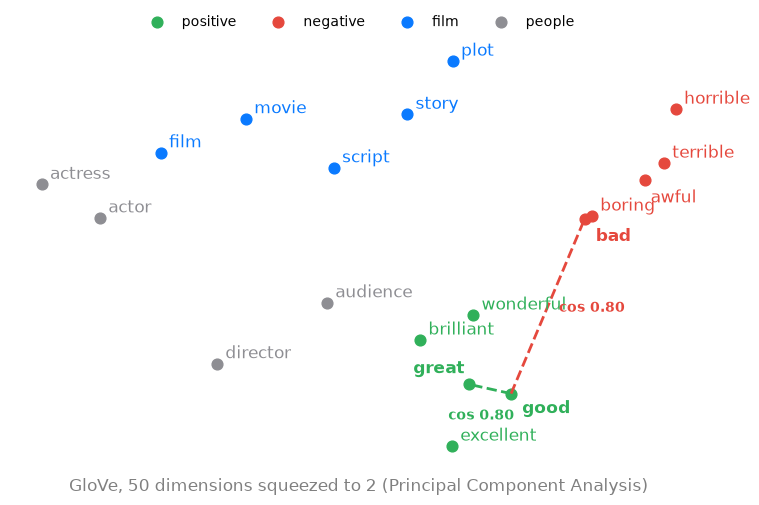

good      · great    0.80
good      · bad      0.80
terrible  · awful    0.89
good      · popcorn  0.27


In [ ]:
from sklearn.decomposition import PCA

groups = {"positive": (["good", "great", "excellent", "wonderful", "brilliant"], "#30B05A"),
          "negative": (["bad", "terrible", "awful", "boring", "horrible"], "#E5483D"),
          "film":     (["movie", "film", "plot", "story", "script"], "#0A7AFF"),
          "people":   (["actor", "actress", "director", "audience"], "#8E8E93")}
plot_words = [w for ws, _ in groups.values() for w in ws]
points = dict(zip(plot_words, PCA(n_components=2).fit_transform(np.array([glove[w] for w in plot_words]))))

offsets = {"bad": (8, -16), "awful": (4, -16), "good": (8, -14), "great": (-40, 8)}   
plt.figure(figsize=(9, 5.5))
for name, (ws, color) in groups.items():
    xy = np.array([points[w] for w in ws])
    plt.scatter(xy[:, 0], xy[:, 1], color=color, s=60, label=name)
    for w in ws:
        bold = "bold" if w in ("good", "great", "bad") else "normal"
        plt.annotate(w, points[w], xytext=offsets.get(w, (6, 4)), textcoords="offset points",
                     color=color, fontsize=12, fontweight=bold)

for other, color, shift in [("great", "#30B05A", (-30, -22)), ("bad", "#E5483D", (8, -4))]:
    (x1, y1), (x2, y2) = points["good"], points[other]
    plt.plot([x1, x2], [y1, y2], ls="--", color=color, lw=2)
    plt.annotate(f"cos {cosine(glove['good'], glove[other]):.2f}", ((x1 + x2) / 2, (y1 + y2) / 2),
                 xytext=shift, textcoords="offset points", color=color, fontweight="bold")

plt.legend(loc="lower center", bbox_to_anchor=(0.5, 1.0), ncol=4, frameon=False)
plt.axis("off")
plt.title("GloVe, 50 dimensions squeezed to 2 (Principal Component Analysis)", color="gray", y=-0.08)
plt.show()

for a_, b_ in [("good", "great"), ("good", "bad"), ("terrible", "awful"), ("good", "popcorn")]:
    print(f"{a_:9} · {b_:8} {cosine(glove[a_], glove[b_]):.2f}")

<span style="color:red;"><b>Question:</b> <i>good</i> and <i>bad</i> are opposites, but their cosine is as high as <i>good</i> and <i>great</i> (0.80). Why? And why does the map still draw <i>good</i> and <i>bad</i> far apart?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**Why 0.80?** GloVe learns from **neighbours**: *good* and *bad* fill the same slots (*"a … movie"*, *"the acting was …"*, *"pretty …"*). Words used in the same places get similar arrows. Nothing ever told GloVe which one is **positive**, so for GloVe, *good* and *bad* are mostly the same kind of word: an opinion about a film.

**Why does the map draw them apart?** There is a **small** positive/negative difference in GloVe. Principal Component Analysis keeps the 2 biggest differences **among the 19 words we plotted**, so that small difference becomes one of the two map directions and looks big. Everything *good* and *bad* have in common is in the other 48 dimensions, which the map leaves out. A map with 2 dimensions can mislead: always check the real cosine.

**What this means for us:** for sentiment, *good* vs *bad* is exactly the difference we need, and GloVe makes it small. So in section 8 our network learns its **own** embeddings from the labelled reviews, where the difference between positive and negative is the whole point.

## 8. Our network: embeddings learned from labels (slides 36–42)

Our network has three steps (slides 36–38):

1. **Embedding layer:** every word gets **64** numbers. They start random and are **weights**, learned by backpropagation from the labelled reviews. This is the network's first layer.
2. **Average:** the vectors of all words in a review are averaged, number by number, into one vector for the whole review (slide 37).
3. **One neuron:** weighted sum + bias = z. z > 0 means positive (that is p > 0.5 after the sigmoid; the sigmoid is built into the loss function).

`nn.EmbeddingBag` does steps 1 and 2 in one go.

In [ ]:
def tokenize(text):
    # lowercase, keep only letters; words with an apostrophe (didn't, it's) stay one word
    return re.findall(r"[a-z]+(?:'[a-z]+)?", text.lower())

counts = Counter(w for text in train_df["text"] for w in tokenize(text))      # uses of every word
itos = ["<unk>"] + [w for w, c in counts.items() if c >= 2]     # itos = "index to string": index -> word
stoi = {w: i for i, w in enumerate(itos)}                       # stoi = "string to index": word -> index
print("Vocabulary size:", len(itos))

def encode(text):
    return torch.tensor([stoi.get(w, 0) for w in tokenize(text)]) 

for s in ["The acting is superb.",              # from pos/cv697_11162.txt
          "I didn't hate it.",                  # tricky sentence 4
          "The Filmkritik was splendiferous."]: # two words the network has never seen
    print(f"{s:36}", tokenize(s), "->", encode(s).tolist())

Vocabulary size: 21396
The acting is superb.                ['the', 'acting', 'is', 'superb'] -> [5, 1001, 112, 1940]
I didn't hate it.                    ['i', "didn't", 'hate', 'it'] -> [3, 746, 4171, 118]
The Filmkritik was splendiferous.    ['the', 'filmkritik', 'was', 'splendiferous'] -> [5, 0, 22, 0]


### Step 2: batches

We don't update the weights after every review, and not only once after all 1,280: we use **batches** of 32 reviews. One update per batch is fast, and averaging the blame over 32 reviews makes every step steadier. Before every epoch we **shuffle** the reviews, so the batches are different each time.

Reviews have different lengths, so `EmbeddingBag` takes all word numbers of a batch in **one long list**, plus the **offsets**: the position where each review starts.

In [27]:
def make_batch(texts):
    ids = [encode(t) for t in texts]                                 
    offsets = torch.tensor([0] + [len(x) for x in ids[:-1]]).cumsum(0)
    return torch.cat(ids), offsets               

ids, offsets = make_batch(["great film", "the plot was boring", "superb"])
print("word numbers:", ids.tolist())
print("offsets:     ", offsets.tolist())
print("-> review 1 starts at 0, review 2 at 0 + 2 = 2, review 3 at 2 + 4 = 6")

def batches(data, batch_size=32, shuffle=False, rng=None):
    order = rng.permutation(len(data)) if shuffle else np.arange(len(data))   
    for start in range(0, len(data), batch_size):
        part = data.iloc[order[start:start + batch_size]]           
        ids, offsets = make_batch(part["text"].tolist())
        yield ids, offsets, torch.tensor(part["y"].values, dtype=torch.float32)   

word numbers: [983, 174, 5, 384, 22, 2358, 1940]
offsets:      [0, 2, 6]
-> review 1 starts at 0, review 2 at 0 + 2 = 2, review 3 at 2 + 4 = 6


### Step 3: the model

Our network in code (slide 38):

- `nn.EmbeddingBag(vocab_size, 64, mode="mean")` is a **table** with one row of 64 numbers for every word in the vocabulary. For a review it looks up the rows of its words and averages them.
- `nn.Dropout(0.3)` switches off 30% of the numbers **at random** while training, so the network can't rely on a few words (it helps against overfitting).
- `nn.Linear(64, 1)` is **one neuron**: 64 weights + 1 bias. Its output is a **score** z; z > 0 means positive.

In [28]:
class SentimentNet(nn.Module):
    def __init__(self, vocab_size, embed_dim=64, dropout=0.3, mode="mean"):
        super().__init__()                                                 
        self.embedding = nn.EmbeddingBag(vocab_size, embed_dim, mode=mode)   
        self.dropout = nn.Dropout(dropout)                                 
        self.output = nn.Linear(embed_dim, 1)                           

    def forward(self, ids, offsets):                                 
        review_vector = self.embedding(ids, offsets)                    
        return self.output(self.dropout(review_vector)).squeeze(1)    
                                                                     
torch.manual_seed(0)                                                        
model = SentimentNet(len(itos))
print(model)
print(f"Number of weights: {sum(p.numel() for p in model.parameters()):,}")
print(f"= {len(itos):,} words × 64 + 64 weights + 1 bias")

SentimentNet(
  (embedding): EmbeddingBag(21396, 64, mode='mean')
  (dropout): Dropout(p=0.3, inplace=False)
  (output): Linear(in_features=64, out_features=1, bias=True)
)
Number of weights: 1,369,409
= 21,396 words × 64 + 64 weights + 1 bias


**What does EmbeddingBag do?** We check the average by hand for *the acting is superb*: look up the 4 rows of the table, average them number by number, and compare with `EmbeddingBag`. We show the first 3 of the 64 numbers.

The network is **not trained yet**, so these numbers are still random: we only check *how* the average works, not what it means.

In [29]:
ids = encode("the acting is superb")
with torch.no_grad():
    rows = model.embedding.weight[ids]                             
    by_hand = rows.mean(dim=0)                               
    by_bag = model.embedding(ids, torch.tensor([0]))[0]          

for word, row in zip(tokenize("the acting is superb"), rows):
    print(f"{word:8} first 3 numbers:", [round(t, 3) for t in row[:3].tolist()])
print()
print("average by hand:            ", [round(t, 3) for t in by_hand[:3].tolist()])
print("average by EmbeddingBag:    ", [round(t, 3) for t in by_bag[:3].tolist()])

the      first 3 numbers: [-0.129, -0.055, 0.408]
acting   first 3 numbers: [1.884, 1.467, 1.383]
is       first 3 numbers: [-0.275, -0.564, 0.971]
superb   first 3 numbers: [1.083, 0.232, 0.796]

average by hand:             [0.641, 0.27, 0.89]
average by EmbeddingBag:     [0.641, 0.27, 0.89]


<span style="color:red;"><b>Question:</b> 21,396 words × 64 numbers = 1.37 million weights, from only 1,280 reviews. What will happen?</span>

### Step 4: train, and watch the validation set

The training loop is the one from section 5, now on real reviews:

- **Loss:** `BCEWithLogitsLoss`, cross-entropy for two classes (slide 19). It applies the sigmoid itself, so the network only outputs a score.
- **Optimizer:** `Adam` does the update step (gradient descent with a step size adapted for every weight, section 5), starting learning rate 0.005.
- **One epoch** = all 1,280 training reviews in shuffled batches of 32: forward, loss, backward, update (40 updates).
- **After every epoch** we measure loss and accuracy on the training **and** the validation reviews. `model.eval()` switches dropout off for measuring, `model.train()` switches it on again for training.
- We **remember the weights of the best validation epoch** and keep those at the end.

20 epochs take about half a minute.

In [30]:
criterion = nn.BCEWithLogitsLoss()                    

def evaluate(model, data):
    model.eval()                                    
    correct, total_loss = 0, 0.0
    with torch.no_grad():                        
        for ids, offsets, labels in batches(data, 256):     
            out = model(ids, offsets)
            correct += ((out > 0).float() == labels).sum().item()   
            total_loss += criterion(out, labels).item() * len(labels)
    return correct / len(data), total_loss / len(data)

def train_net(model, epochs=20, lr=0.005, verbose=True):
    optimizer = torch.optim.Adam([p for p in model.parameters() if p.requires_grad], lr=lr)
    rng = np.random.default_rng(0)                          
    history, best_val, best_epoch, best_state = [], 0, None, None
    for epoch in range(1, epochs + 1):
        model.train()                                      
        for ids, offsets, labels in batches(train_df, 32, shuffle=True, rng=rng):
            loss = criterion(model(ids, offsets), labels)   #
            optimizer.zero_grad()                          
            loss.backward()                               
            optimizer.step()                               
        (tr_acc, tr_loss), (va_acc, va_loss) = evaluate(model, train_df), evaluate(model, val_df)
        history.append((epoch, tr_loss, va_loss, tr_acc, va_acc))
        if va_acc > best_val:                             
            best_val, best_epoch = va_acc, epoch
            best_state = {k: v.clone() for k, v in model.state_dict().items()}   
        if verbose:
            print(f"epoch {epoch:2d} | loss train {tr_loss:.3f} val {va_loss:.3f} | acc train {tr_acc:.1%} val {va_acc:.1%}")
    model.load_state_dict(best_state)                      
    return pd.DataFrame(history, columns=["epoch", "train loss", "val loss", "train acc", "val acc"]), best_epoch

start = time.time()
torch.manual_seed(0)
model = SentimentNet(len(itos))
h, best_epoch = train_net(model)
print(f"Best validation epoch: {best_epoch}. Training took {time.time() - start:.0f} seconds")

epoch  1 | loss train 0.680 val 0.684 | acc train 51.9% val 50.6%
epoch  2 | loss train 0.641 val 0.661 | acc train 81.8% val 74.4%
epoch  3 | loss train 0.550 val 0.608 | acc train 90.9% val 79.7%
epoch  4 | loss train 0.422 val 0.536 | acc train 93.7% val 81.2%
epoch  5 | loss train 0.303 val 0.478 | acc train 95.7% val 81.6%
epoch  6 | loss train 0.212 val 0.424 | acc train 97.9% val 84.1%
epoch  7 | loss train 0.149 val 0.398 | acc train 99.1% val 83.1%
epoch  8 | loss train 0.107 val 0.376 | acc train 99.6% val 84.1%
epoch  9 | loss train 0.080 val 0.376 | acc train 99.6% val 84.4%
epoch 10 | loss train 0.059 val 0.359 | acc train 99.8% val 84.7%
epoch 11 | loss train 0.046 val 0.357 | acc train 100.0% val 85.3%
epoch 12 | loss train 0.036 val 0.353 | acc train 100.0% val 85.6%
epoch 13 | loss train 0.029 val 0.340 | acc train 100.0% val 85.6%
epoch 14 | loss train 0.023 val 0.343 | acc train 100.0% val 86.9%
epoch 15 | loss train 0.020 val 0.341 | acc train 100.0% val 85.9%
epoch

<span style="color:red;"><b>Question:</b> From epoch 11 on, the network gets <b>every</b> training review right (100%). Does that mean it is finished learning? Look at the validation accuracy.</span>

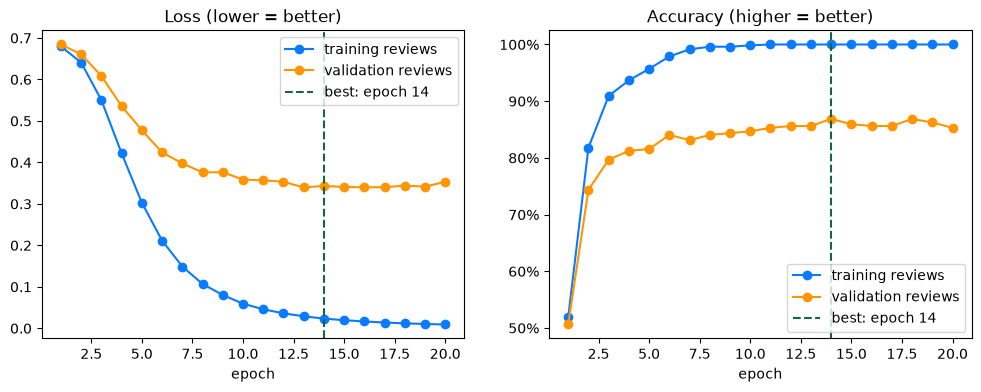

validation loss: lowest 0.340 at epoch 13, at the end 0.353 (going up again) | training loss at the end 0.009


In [31]:
from matplotlib.ticker import PercentFormatter

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, col, title in [(axes[0], "loss", "Loss (lower = better)"), (axes[1], "acc", "Accuracy (higher = better)")]:
    ax.plot(h["epoch"], h[f"train {col}"], marker="o", label="training reviews", color="#0A7AFF")
    ax.plot(h["epoch"], h[f"val {col}"], marker="o", label="validation reviews", color="#FF9500")
    ax.axvline(best_epoch, color="#17663A", linestyle="--", label=f"best: epoch {best_epoch}")
    ax.set_title(title); ax.set_xlabel("epoch"); ax.legend()
axes[1].yaxis.set_major_formatter(PercentFormatter(1.0))      
plt.show()

low = h["val loss"].idxmin()
print(f"validation loss: lowest {h['val loss'][low]:.3f} at epoch {h['epoch'][low]}, "
      f"at the end {h['val loss'].iloc[-1]:.3f} (going up again) | training loss at the end {h['train loss'].iloc[-1]:.3f}")

**What each number tells us** (from our run above):

| | Training reviews | Validation reviews |
|---|---|---|
| **Accuracy** | Has it learned the training reviews?<br>100% from epoch 11 | How good is it on **new** reviews?<br>best 86.9% at epoch 14, then up and down between 85% and 87% |
| **Loss** | Is it still changing?<br>keeps falling: 0.046 (epoch 11) → 0.009 (epoch 20) | Is it getting worse on new reviews?<br>lowest about 0.340 (epochs 13–17), then up to 0.353 |

**Overfitting** = the training numbers keep getting better while the validation numbers stop improving or get worse.

We pick the best epoch by validation **accuracy** (epoch 14). Many people use validation **loss** instead: it changes more smoothly, because on 320 reviews accuracy can only move in steps of one review (0.3%). Here both point to about the same epochs.

<span style="color:green;"><b>Answer:</b></span><br>
**Overfitting.** With about 1,000 weights per training review (1.37 million weights, 1,280 reviews), the network can **memorise** the training reviews.

**Is it finished learning at 100%?** No. Accuracy only counts right or wrong, but the training **loss** keeps falling after epoch 11 (0.046 → 0.009): the network keeps changing its weights to become **more sure** about reviews it already gets right. That doesn't help on new reviews: validation accuracy just moves up and down between 85% and 87%, and validation **loss** even goes up again at the end. From there, the network only learns details of the 1,280 training reviews.

It still learned something useful: 86% on reviews it has never seen. Overfitting doesn't make a model useless, it means **more training no longer helps**.

In [32]:
best, waited = 0, 0
for epoch, va in zip(h["epoch"], h["val acc"]):
    if va > best:                   
        best, waited = va, 0
    else:                              
        waited += 1
    print(f"epoch {epoch:2d} | val acc {va:.1%} | best so far {best:.1%} | epochs without improvement: {waited}")
    if waited == 5:
        print(f"\npatience 5 would stop at epoch {epoch}, and keep the weights of the best epoch")
        break

epoch  1 | val acc 50.6% | best so far 50.6% | epochs without improvement: 0
epoch  2 | val acc 74.4% | best so far 74.4% | epochs without improvement: 0
epoch  3 | val acc 79.7% | best so far 79.7% | epochs without improvement: 0
epoch  4 | val acc 81.2% | best so far 81.2% | epochs without improvement: 0
epoch  5 | val acc 81.6% | best so far 81.6% | epochs without improvement: 0
epoch  6 | val acc 84.1% | best so far 84.1% | epochs without improvement: 0
epoch  7 | val acc 83.1% | best so far 84.1% | epochs without improvement: 1
epoch  8 | val acc 84.1% | best so far 84.1% | epochs without improvement: 2
epoch  9 | val acc 84.4% | best so far 84.4% | epochs without improvement: 0
epoch 10 | val acc 84.7% | best so far 84.7% | epochs without improvement: 0
epoch 11 | val acc 85.3% | best so far 85.3% | epochs without improvement: 0
epoch 12 | val acc 85.6% | best so far 85.6% | epochs without improvement: 0
epoch 13 | val acc 85.6% | best so far 85.6% | epochs without improvement: 1

### Step 5: the test set, once

All decisions are made: the vocabulary, the settings, the epoch (14). Now, and **only now**, we measure the 400 test reviews: the same 400 as for TextBlob and logistic regression, so the scoreboard is fair.

In [33]:
results["3. Neural network (EmbeddingBag)"] = evaluate(model, test_df)[0]    
val_acc = evaluate(model, val_df)[0]
print(f"Model from epoch {best_epoch}:")
print(f"  validation accuracy: {val_acc:.1%}  (used to choose the epoch)")
print(f"  test accuracy:       {results['3. Neural network (EmbeddingBag)']:.1%}  (never used for any decision)")

Model from epoch 14:
  validation accuracy: 86.9%  (used to choose the epoch)
  test accuracy:       85.0%  (never used for any decision)


### *(Try it)* Bigger, borrowed or combined differently? 

Every choice we made for our network is a **hyperparameter**: something we set before training, not learned. We try a few others, each time training a **new** network (this cell takes a few minutes):

| Name | What changes |
|---|---|
| own, 16 / 64 / 128 / 256 | how many numbers per word (ours: 64) |
| GloVe frozen | start from GloVe's 50 numbers and **don't** change them: only the output neuron learns |
| GloVe + learned | start from GloVe, then keep learning from the labels |
| sum / max instead of average | how the word vectors are combined into one review vector |

We **choose by validation**. The test column is shown only to complete the picture on slides 37 and 40: in a real project we would not look at it until the very end.

In [34]:
def try_setting(embed_dim=64, mode="mean", use_glove=False, freeze=False, epochs=20, lr=0.005):
    torch.manual_seed(0)                                
    m = SentimentNet(len(itos), embed_dim, mode=mode)
    if use_glove:                                   
        with torch.no_grad():
            for w, i in stoi.items():
                if w in glove:                         
                    m.embedding.weight[i] = torch.tensor(glove[w])
        m.embedding.weight.requires_grad = not freeze  
    hist, ep = train_net(m, epochs=epochs, lr=lr, verbose=False)
    return {"best epoch": ep, "validation": round(100 * hist["val acc"].max(), 1),
            "test": round(100 * evaluate(m, test_df)[0], 1)}

print(f"Words with a GloVe vector: {sum(w in glove for w in itos):,} of {len(itos):,}")

experiments = {
    "own, 16": dict(embed_dim=16), "own, 64 (ours)": dict(), "own, 128": dict(embed_dim=128), "own, 256": dict(embed_dim=256),
    "GloVe frozen": dict(embed_dim=50, use_glove=True, freeze=True, epochs=40, lr=0.01),
    "GloVe + learned": dict(embed_dim=50, use_glove=True),
    "sum instead of average": dict(mode="sum"), "max instead of average": dict(mode="max"),
}
rows = {}
for name, kw in experiments.items():
    start = time.time()
    rows[name] = try_setting(**kw)
    print(f"{name:24} done in {time.time() - start:.0f} s")
pd.DataFrame.from_dict(rows, orient="index")

Words with a GloVe vector: 18,963 of 21,396
own, 16                  done in 10 s
own, 64 (ours)           done in 11 s
own, 128                 done in 14 s
own, 256                 done in 20 s
GloVe frozen             done in 19 s
GloVe + learned          done in 12 s
sum instead of average   done in 12 s
max instead of average   done in 13 s


,best epoch,validation,test
"own, 16",18,84.7,85.0
"own, 64 (ours)",14,86.9,85.0
"own, 128",15,87.2,86.2
"own, 256",6,86.2,84.8
GloVe frozen,27,65.9,67.0
GloVe + learned,11,85.0,85.5
sum instead of average,9,80.6,78.5
max instead of average,13,66.6,63.5


<span style="color:red;"><b>Question:</b> Will more numbers per word (128, 256) be better? Will starting from GloVe help? Which way of combining will be best: average, sum or max?</span>

<span style="color:green;"><b>Answer:</b></span><br>
- **Bigger ≠ better:** 16 to 256 numbers per word all give about 85–87%. 128 has the best validation (87.2%), but 0.3% more than ours is **one** of 320 reviews: too small to matter (like in section 2). 256 overfits sooner: best epoch 6, not 14.
- **GloVe frozen** only gets about 67%: in GloVe *good* and *bad* are close (section 7), so averaging washes the sentiment out, and the frozen vectors can't learn the difference.
- **GloVe + learned** reaches 85.5%: it works, but no better than starting at random. 1,280 labelled reviews are enough to learn our own vectors here. Borrowed vectors help most when there is **little** labelled data.
- **Average** beats **sum** and **max**. With sum, a long review gets much bigger numbers than a short one, so length matters more than content. With max, every number comes from one extreme word, and all the other words are ignored.

### What did our network learn?

Two ways to look inside the trained network:

**1. Cosine** between our network's word vectors, next to GloVe's (section 7).

**2. Push.** In section 3, every word **pushed** the score of logistic regression up or down: its push was weight × TF-IDF value (w·x). Our network has a push for every word too:

- The output neuron computes the score from the **average** of the word vectors.
- If we give it the vector of **one** word on its own, we get that word's push: the score of a review that contains only this word.
- Positive push = the word pulls towards *positive*, negative push = towards *negative*.

The numbers look big (some are over 50) because in a real review the vectors are **averaged**: in a review of 700 words, every word brings only about 1/700 of its push. What matters is the sign and how the words rank.

We only rank words used at least 20 times, so rare words with random-looking vectors don't fill the list.

In [35]:
with torch.no_grad():
    vec = model.embedding.weight.numpy()                                
    push = model.output(model.embedding.weight).squeeze(1).numpy()       

# 1. cosine: GloVe vs our network
for a_, b_ in [("good", "great"), ("good", "bad"), ("great", "awful"), ("terrible", "awful")]:
    print(f"{a_:9} · {b_:6}  GloVe {cosine(glove[a_], glove[b_]):+.2f} | our network {cosine(vec[stoi[a_]], vec[stoi[b_]]):+.2f}")

# 2. push: rank the words used at least 20 times in training
frequent = [i for i, w in enumerate(itos) if counts[w] >= 20]
ranked = sorted(frequent, key=lambda i: push[i])                        
print("\nPushes most negative:", [itos[i] for i in ranked[:10]])
print("Pushes most positive:", [itos[i] for i in ranked[-10:]])
print()
for w in ["splendid", "dismal", "flaws", "plot"]:
    print(f"{w:9} push {push[stoi[w]]:+.1f}  (used {counts[w]} times in training)")

good      · great   GloVe +0.80 | our network +0.36
good      · bad     GloVe +0.80 | our network -0.47
great     · awful   GloVe +0.51 | our network -0.62
terrible  · awful   GloVe +0.89 | our network +0.72

Pushes most negative: ['worst', 'mess', 'nothing', 'inept', 'ridiculous', 'bad', 'awful', 'looks', 'poorly', 'supposed']
Pushes most positive: ['refreshing', 'tunes', "i've", 'flaws', 'anger', 'thankfully', 'wonderfully', 'terrific', 'overall', 'definitely']

splendid  push +29.6  (used 7 times in training)
dismal    push +3.1  (used 12 times in training)
flaws     push +84.5  (used 70 times in training)
plot      push -74.6  (used 954 times in training)


**What we see:** trained with labels, *good* and *bad* point in opposite directions. Surprises: *flaws* is positive (*"despite its flaws…"*), *plot* is negative. *splendid* (rare) became positive; *dismal* (rare) is still about 0: problem 1 is only **partly** solved.

<span style="color:red;"><b>Question:</b> <i>supposed</i> and <i>looks</i> are among the most negative words, <i>flaws</i> is among the most positive. None of them is an opinion word. Why did the network learn this?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**Cosine:** trained with labels, *good* and *bad* now point in **opposite** directions (−0.47 instead of +0.80 in GloVe), and so do *great* and *awful*. *terrible* and *awful* stay close (+0.72): same meaning **and** same sentiment.

**The surprising words:** the network learns from **which reviews a word appears in**, not from its dictionary meaning. In all 2,000 reviews:
- *supposed* is used 240× in negative and 83× in positive reviews: *"it was **supposed to be** funny"* is a complaint.
- *looks* is 279× negative, 164× positive: *"it **looks like** a TV movie"*.
- *flaws* is 86× **positive**, 29× negative: people who liked a film write *"despite its flaws"*, *"minor flaws"*.
- *plot* is 917× negative, 596× positive: unhappy reviewers talk about the plot.

**Rare words:** *splendid* (7 uses) became positive, but *dismal* (12 uses) is still close to 0. With so few examples the network can't always learn a word well: the problem from section 7 is only **partly** solved.

### The tricky sentences

Our network is the best so far on the 400 test reviews: 85.0%, against 80.2% for logistic regression and 59.5% for TextBlob. Now the 8 tricky sentences.<br>
**P(positive)** = the network's probability that the sentence is positive. **0.5 is the line:** above 0.5 → *pos*, below → *neg*. The further from 0.5, the surer the network.

In [36]:
def predict_net(sentences):
    model.eval()                                         
    with torch.no_grad():
        ids, offsets = make_batch(sentences)
        return torch.sigmoid(model(ids, offsets)).numpy() 

probs_tricky = predict_net(tricky["sentence"].tolist())
tricky["Neural net"] = np.where(probs_tricky > 0.5, "pos", "neg")
tricky["net prob."] = probs_tricky.round(2)
tricky["net right?"] = np.where(tricky["Neural net"] == tricky["truth"], "✓", "✗")
print("Neural net correct:", (tricky["net right?"] == "✓").sum(), "of 8")
display(tricky[["sentence", "truth", "Neural net", "net prob.", "net right?"]])

for s in ["This movie was not good.", "This movie was good not."]:
    print(f"{s:28} -> probability positive {predict_net([s])[0]:.3f}")

Neural net correct: 3 of 8


,sentence,truth,Neural net,net prob.,net right?
0,This movie was great!,pos,pos,1.00,✓
1,This movie was not good.,neg,neg,0.46,✓
2,"Not bad at all, I really enjoyed it.",pos,neg,0.25,✗
3,I didn't hate it.,pos,neg,0.00,✗
4,"I loved the trailer, but the film was a disaster.",neg,pos,0.99,✗
5,"Oh great, another two hours of my life I will never get back.",neg,pos,1.00,✗
6,The acting was terrible but the story was wonderful.,pos,neg,0.00,✗
7,"Absolutely brilliant, a must-see!",pos,pos,1.00,✓


This movie was not good.     -> probability positive 0.457
This movie was good not.     -> probability positive 0.457


<span style="color:red;"><b>Question:</b> At the start of section 8 we asked what averaging loses. Now check: <i>"This movie was not good."</i> and <i>"This movie was good not."</i> get exactly the same probability. Why? And what does that mean for <i>"I didn't hate it"</i>, the <i>but</i> sentences and sarcasm?</span>

<span style="color:green;"><b>Answer:</b></span><br>
**Same words, same average.** The average of the word vectors doesn't change when we change the order, so both sentences get exactly 0.457. Our network is still a **bag of words**, only with smarter word vectors.

What that means for the tricky sentences:
- ***"I didn't hate it"*** (0.00): *hate* pushes strongly negative, *didn't* only a little. In an average *didn't* can't **flip** *hate*: it is just one more word in the mix.
- **The *but* sentences:** both halves go into the same average, and the strongest words win. *disaster* loses to *loved* (0.99, wrong), *terrible* beats *wonderful* (0.00, wrong). The network can't see that *but* makes the second half more important.
- **Sarcasm** (*"Oh great, another two hours..."*, 1.00): *great* pushes positive, and nothing in the average says "meant ironically".

**Very sure, and wrong.** Of the 5 wrong answers, 4 are at 0.00 or 0.99–1.00. The network trained until it was very sure about its training reviews (section 8, step 4), so it is very sure about everything, including its mistakes. A high probability is not a guarantee.

To read *didn't* together with *hate*, a model must look at each word **in the context of the other words**. That is what transformers do: **next lesson**.

## 9. Scoreboard

In [37]:
tricky_right = [int((tricky[m] == tricky["truth"]).sum()) for m in ["TextBlob", "Log. reg.", "Neural net"]]
scoreboard = pd.DataFrame({
    "lesson": [1, 1, 2, 3],
    "test accuracy (400 reviews)": [f"{v:.1%}" for v in results.values()] + ["?"],
    "tricky sentences (of 8)": [f"{t}/8" for t in tricky_right] + ["?"],
}, index=list(results.keys()) + ["4. Pretrained transformer"])
scoreboard

,lesson,test accuracy (400 reviews),tricky sentences (of 8)
1. Rules: TextBlob,1,59.5%,4/8
2. TF-IDF + logistic regression,1,80.2%,2/8
3. Neural network (EmbeddingBag),2,85.0%,3/8
4. Pretrained transformer,3,?,?


## 10. *(Optional)* Marvin, the friendly chatbot, with embeddings

Marvin is a small chatbot that talks about films. It is built from three parts, each using what we learned today:

| Part | What it does | Built with |
|---|---|---|
| 1. Mood | How positive is the message? | our sentiment network from section 8 (**learned** embeddings) |
| 2. Topic | Which film topic is the message about? | **GloVe** cosine (section 7): the topic closest to any word of the message |
| 3. Follow-up | What to ask next? | **GloVe** cosine: the topic closest to the current one |

Because Marvin compares **vectors**, not exact words, it understands words that are not in its topic list: *scary* is close to *horror*, *songs* to *soundtrack*.

In [38]:
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

# the film topics Marvin can talk about
TOPICS = ["comedy", "horror", "thriller", "romance", "western", "animation", "documentary", "musical", "war", "fantasy",
          "actor", "actress", "director", "plot", "ending", "dialogue", "soundtrack", "effects", "costumes", "cinema"]
IGNORE = {"film", "films", "movie", "movies", "love", "like", "really", "today", "yesterday"}   # too general to be a topic

def find_mood(message):
    """Part 1: how positive is the message? Our network from section 8 (learned embeddings)."""
    return float(predict_net([message])[0])

def find_topic(message, min_similarity=0.65):
    """Part 2: which topic is closest to a word of the message? GloVe cosine (section 7)."""
    best_topic, best_word, best_sim = None, None, min_similarity
    for w in tokenize(message):
        if w in ENGLISH_STOP_WORDS or w in IGNORE or w not in glove:
            continue
        for t in TOPICS:
            sim = cosine(glove[w], glove[t])
            if sim > best_sim:
                best_topic, best_word, best_sim = t, w, sim
    return best_topic, best_word

def next_topic(topic):
    """Part 3: the topic closest to this one, for a follow-up question."""
    return max((t for t in TOPICS if t != topic), key=lambda t: cosine(glove[topic], glove[t]))

def marvin(message):
    p_pos = find_mood(message)
    if p_pos > 0.7:
        reply = random.choice(["That sounds great!", "Wonderful, I'm happy for you!"])
    elif p_pos < 0.3:
        reply = random.choice(["Oh no, that sounds disappointing.", "I'm sorry to hear that."])
    else:
        reply = random.choice(["I see.", "Hmm, tell me more."])
    reply += f" (I'm {p_pos:.0%} sure you liked it.)"

    topic, word = find_topic(message)
    if topic is None:
        return reply + " What kind of films do you like?"
    if word != topic:
        reply += f" '{word}' sounds like {topic} to me."
    return reply + f" And what do you think about {next_topic(topic)}?"

random.seed(1)
for message in ["I watched an amazing science fiction film yesterday",
                "The songs were so catchy",
                "The plot was boring and the acting was terrible",
                "I fell asleep during the scary movie",
                "I didn't hate the new comedy",
                "The weather is nice today"]:
    print("You:   ", message)
    print("Marvin:", marvin(message))
    print()

You:    I watched an amazing science fiction film yesterday
Marvin: That sounds great! (I'm 100% sure you liked it.) 'fiction' sounds like fantasy to me. And what do you think about horror?

You:    The songs were so catchy
Marvin: That sounds great! (I'm 97% sure you liked it.) 'songs' sounds like soundtrack to me. And what do you think about musical?

You:    The plot was boring and the acting was terrible
Marvin: I'm sorry to hear that. (I'm 0% sure you liked it.) And what do you think about thriller?

You:    I fell asleep during the scary movie
Marvin: Oh no, that sounds disappointing. (I'm 0% sure you liked it.) 'scary' sounds like horror to me. And what do you think about thriller?

You:    I didn't hate the new comedy
Marvin: I'm sorry to hear that. (I'm 0% sure you liked it.) And what do you think about musical?

You:    The weather is nice today
Marvin: Wonderful, I'm happy for you! (I'm 100% sure you liked it.) What kind of films do you like?



To chat with Marvin yourself, remove the `#` in front of the lines below and run the cell. Type **bye** to stop.

In [39]:
# print("Hello, I am Marvin, I love talking about films. Type 'bye' to stop.")
# while True:
#     user_input = input("> ")
#     if user_input.lower() == "bye":
#         print("It was nice talking to you, goodbye!")
#         break
#     print(marvin(user_input))

## 11. *(Optional)* A text generator: a neural network with a hidden layer

In lesson 1 the n-gram generator **counted** which word follows. Now a neural network **learns** it. Unlike our sentiment network (average + one neuron), this one has a real **hidden layer**, like the small network of section 4:

| Layer | What it does | Section |
|---|---|---|
| 1. Embedding | each of the last 3 words → 32 numbers | 8 |
| 2. Hidden layer | 3 × 32 = 96 inputs → 128 neurons with **ReLU** | 4 |
| 3. Output | 128 → one score for each of 5,000 words, **softmax** turns them into probabilities | 4 (slide 14) |

It is trained with the loop of section 5: forward, **cross-entropy** loss, backward, update (Adam), in batches of 512, for 3 epochs. Training takes about 1.5 minutes.

In [40]:
def tokens_with_punct(text):
    return re.findall(r"[a-z]+(?:'[a-z]+)?|[.!?]", text.lower())    

all_tokens = [w for t in train_df["text"] for w in tokens_with_punct(t)]
gen_vocab = ["<unk>"] + [w for w, _ in Counter(all_tokens).most_common(4999)]  
gen_idx = {w: i for i, w in enumerate(gen_vocab)}
ids_all = torch.tensor([gen_idx.get(w, 0) for w in all_tokens])

CONTEXT = 3                                                                
X_gen = torch.stack([ids_all[i:len(ids_all) - CONTEXT + i] for i in range(CONTEXT)], dim=1)   
Y_gen = ids_all[CONTEXT:]                                                
keep = Y_gen != 0                                                      
X_gen, Y_gen = X_gen[keep], Y_gen[keep]

print("Tokens in the training reviews:", f"{len(all_tokens):,}")
print("Training examples (3 words -> next word):", f"{len(Y_gen):,}")
print("Example:", [gen_vocab[i] for i in X_gen[100]], "->", gen_vocab[Y_gen[100]])

Tokens in the training reviews: 879,067
Training examples (3 words -> next word): 786,542
Example: ['marriage', '.', 'a'] -> man


In [41]:
class NextWordNet(nn.Module):
    def __init__(self, vocab_size, embed_dim=32, hidden=128):
        super().__init__()
        self.embedding = nn.Embedding(vocab_size, embed_dim)      
        self.hidden = nn.Linear(CONTEXT * embed_dim, hidden)           
        self.output = nn.Linear(hidden, vocab_size)                

    def forward(self, x):
        e = self.embedding(x).flatten(1)      
        h = torch.relu(self.hidden(e))       
        return self.output(h)                   

torch.manual_seed(0)
gen = NextWordNet(len(gen_vocab))
print(gen)
for name, p in gen.named_parameters():
    print(f"{name:16} {str(tuple(p.shape)):12} {p.numel():>9,} weights")
print(f"{'total':16} {'':12} {sum(p.numel() for p in gen.parameters()):>9,} weights")

NextWordNet(
  (embedding): Embedding(5000, 32)
  (hidden): Linear(in_features=96, out_features=128, bias=True)
  (output): Linear(in_features=128, out_features=5000, bias=True)
)
embedding.weight (5000, 32)     160,000 weights
hidden.weight    (128, 96)       12,288 weights
hidden.bias      (128,)             128 weights
output.weight    (5000, 128)    640,000 weights
output.bias      (5000,)          5,000 weights
total                           817,416 weights


In [42]:
def next_word_probs(text, top=5):
    """Forward pass for the last 3 words: the 5 most likely next words (softmax, slide 14)."""
    x = torch.tensor([[gen_idx.get(w, 0) for w in tokens_with_punct(text)[-CONTEXT:]]])
    gen.eval()
    with torch.no_grad():
        p = torch.softmax(gen(x)[0], dim=0)
    best = torch.topk(p, top)
    return [(gen_vocab[i], round(float(q), 4)) for q, i in zip(best.values, best.indices)]

print("Before training:", next_word_probs("the acting is"))

Before training: [('blown', 0.0005), ('argument', 0.0005), ('unless', 0.0004), ('particular', 0.0004), ('grant', 0.0004)]


In [43]:
optimizer = torch.optim.Adam(gen.parameters(), lr=0.003)
loss_fn = nn.CrossEntropyLoss()                      
shuffle_gen = torch.Generator().manual_seed(0)

start = time.time()
for epoch in range(3):
    gen.train()
    order = torch.randperm(len(Y_gen), generator=shuffle_gen)      
    total = 0
    for b in range(0, len(Y_gen), 512):                              
        batch = order[b:b + 512]
        loss = loss_fn(gen(X_gen[batch]), Y_gen[batch])            
        optimizer.zero_grad()
        loss.backward()                                              
        optimizer.step()                                           
        total += loss.item() * len(batch)
    print(f"epoch {epoch + 1} | loss {total / len(Y_gen):.2f} | {time.time() - start:.0f} s")

epoch 1 | loss 5.72 | 11 s
epoch 2 | loss 5.22 | 24 s
epoch 3 | loss 5.04 | 37 s


In [44]:
for text in ["the acting is", "this movie was", "the special effects"]:
    print(f"{text:20} ->", next_word_probs(text))

the acting is        -> [('a', 0.0974), ('the', 0.0403), ('also', 0.0271), ('not', 0.0249), ('that', 0.0169)]
this movie was       -> [('a', 0.0675), ('the', 0.0488), ('not', 0.0405), ('that', 0.0267), ('so', 0.0222)]
the special effects  -> [('are', 0.1945), ('.', 0.1365), ('and', 0.0602), ('were', 0.0571), ('have', 0.0266)]


In [45]:
def generate(seed, length=20, temperature=0.8):
    words = tokens_with_punct(seed)
    gen.eval()
    for _ in range(length):
        x = torch.tensor([[gen_idx.get(w, 0) for w in words[-CONTEXT:]]])
        with torch.no_grad():
            scores = gen(x)[0]
        scores[0] = -1e9                                             # never pick <unk>
        if temperature == 0:
            nxt = int(scores.argmax())                               # always the most likely word
        else:
            p = torch.softmax(scores / temperature, dim=0)           # temperature: lower = safer, higher = wilder
            nxt = int(torch.multinomial(p, 1, generator=shuffle_gen))
        words.append(gen_vocab[nxt])
    return " ".join(words)

shuffle_gen.manual_seed(1)
print("temperature 0:  ", generate("the acting is", temperature=0))
for t in [0.5, 0.8, 1.2]:
    print(f"temperature {t}:", generate("the acting is", temperature=t))

temperature 0:   the acting is a good film . the film is a good film . the film is a good film . the film
temperature 0.5: the acting is a solid . the girls is a new movie . it's a shame that the movie is also a little
temperature 0.8: the acting is about to get married and worse . the movie's the enterprise . derek and we are listening . that comes
temperature 1.2: the acting is to he played in her over six it answers for mediocre maybe weird when i killed has absolutely no fault


## 12. Recap

| Section | What we learned |
|---|---|
| 1. Data | Training (learn), validation (choose), test (measure **once**). Same 400 test reviews as lesson 1. |
| 2. Vocabulary | Vocabulary size = number of features. `min_df` and `max_features` cut the rare tail, stop words cut the top (and remove *not*). |
| 3. One neuron | Logistic regression = weighted sum + bias + sigmoid. Every word **pushes** the score; the bias balances the average push. The threshold is our choice, not learned. |
| 4. Forward | Tensors, a layer = a matrix multiplication, activations (ReLU, sigmoid, softmax) as the bend. Without a bend, many layers = one neuron. |
| 5. Learning | Forward → loss → backpropagation (blame for every weight) → gradient descent, in batches and epochs. The learning rate is the step size: too small is slow, too big explodes. |
| 6. Validation | A training loss of 0 doesn't prove anything: a model only learns from what is in its data. |
| 7. GloVe | Words as vectors, learned from their neighbours. Similar words are close, but so are *good* and *bad*. |
| 8. Our network | Embeddings learned from labels: *good* and *bad* now point apart. It overfits (100% on training), so we keep the best validation epoch: 85.0% on the test set. Still a bag of words, and very sure even when wrong. |
| 9. Scoreboard | Best on real reviews (85.0%), but only 3 of 8 tricky sentences. |
| 10–11. Project examples | Marvin: a chatbot from our network + GloVe. A text generator: embedding, hidden layer, softmax. |

**Key takeaways:**

- **A neural network is neurons in layers**, trained with forward pass, loss, backpropagation and gradient descent.
- **Always watch a validation set**: networks overfit easily. Choose with validation, test **once**.
- **Embeddings** give every word a vector. Learned with labels, they capture sentiment.
- **Averaging word vectors** is still a bag of words: no order, no context. *"not good"* = *"good not"*.

**Next lesson: transformers.** Models that read every word **in the context of the others**, pretrained on huge amounts of text, and the final showdown of all four methods.